# Báo Cáo Phân Tích Dữ Liệu Bất Động Sản TP.HCM (EDA & Trực Quan Hóa)

**Tập dữ liệu:** `Data/v3/master_v3.csv` (6.703 tin đăng, 252 thuộc tính)  
**Nội dung thực hiện:**
1. **Tổng quan & Cơ cấu loại hình BĐS** (Pie / Donut Chart)
2. **Nhóm 1: Phân tích Không gian & Địa lý (Spatial & Geographic Analysis)**
   * Top 12 Khu vực / Quận huyện cũ có nguồn cung dẫn đầu
   * Top 10 Phường / Xã mới sau sáp nhập có nguồn cung lớn nhất
   * Trích xuất, chuẩn hóa và lọc tọa độ GPS ngoại lai
   * Bản đồ phân bố không gian BĐS theo loại hình (Spatial Scatter Map)

In [72]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập font và style hiển thị
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Segoe UI']
plt.rcParams['axes.unicode_minus'] = False
os.makedirs('figures', exist_ok=True)

# 1. Đọc dữ liệu
data_path = '../Data/v3/master_v3.csv'
if not os.path.exists(data_path):
    data_path = 'Data/v3/master_v3.csv'

df = pd.read_csv(data_path)
df['area'] = pd.to_numeric(df['area'], errors='coerce')
print(f"Tổng số tin đăng trong dataset: {len(df):,} tin | Số cột: {len(df.columns)}")
df.head(2)

Tổng số tin đăng trong dataset: 6,703 tin | Số cột: 252


C:\Users\Dell\AppData\Local\Temp\ipykernel_4472\3441782634.py:17: DtypeWarning: Columns (16,154,241,247,248) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path)


,listing_id,listing_type,posted_date,expiry_date,property_type,city_province,district,Folder,title,address,...,address_new,address_old,address_new_normalized,address_old_normalized,source,prev_posted_date,prev_expiry_date,prev_price_range,images,image_count
0,18155030,Tin thường,23/09/2026,08/10/2026,"Nhà biệt thự, liền kề",Hồ Chí Minh,Phường Long Trường,"Bán/Hồ Chí Minh/Long Trường/Nhà biệt thự, liền...","Giá ngộp Melosa Khang Điền 115m2, có nội thất ...","Melosa Garden, Phường Long Trường, Hồ Chí Minh",...,"Melosa Garden, Phường Long Trường, Hồ Chí Minh","Quận 9, Hồ Chí Minh cũ",melosa garden phuong long truong ho chi minh,quan 9 ho chi minh cu,new,NaN,NaN,NaN,"[""images/Nhà biệt thự, liền kề/Phươ...",4
1,24712656,Tin thường,27/09/2026,12/10/2026,Căn hộ chung cư,Hồ Chí Minh,Phường Thạnh Mỹ Tây,Bán/Hồ Chí Minh/Thạnh Mỹ Tây/Căn hộ chung cư t...,"Chính chủ nhà gửi bán CH Green Field, Quận Bìn...","Green Field, Đường Xô Viết Nghệ Tĩnh, Phường T...",...,"Green Field, Đường Xô Viết Nghệ Tĩnh, Phường T...","Quận Bình Thạnh, Hồ Chí Minh cũ",green field duong xo viet nghe tinh phuong tha...,quan binh thanh ho chi minh cu,new,NaN,NaN,NaN,"[""images/Căn hộ chung cư/Phường Thạnh ...",5


In [73]:
# Chuẩn hóa đồng nhất property_type về 5 nhóm chuẩn của dataset gốc
def standardize_property_type(row):
    pt = row.get('property_type')
    title = str(row.get('title', '')).lower()
    if pt == 'Căn hộ':
        return 'Căn hộ chung cư'
    if pt == 'Nhà đất':
        if any(k in title for k in ['shophouse', 'shop house', 'nhà phố thương mại']):
            return 'Shophouse, nhà phố thương mại'
        if any(k in title for k in ['biệt thự', 'villa', 'liền kề', 'compound']):
            return 'Nhà biệt thự, liền kề'
        if any(k in title for k in ['mặt tiền', 'mặt phố', 'mt đường']):
            return 'Nhà mặt phố'
        return 'Nhà riêng'
    return pt

df['property_type'] = df.apply(standardize_property_type, axis=1)

--- 
## 1. Cơ Cấu Loại Hình Bất Động Sản (Property Types Distribution)
Thống kê số lượng, tỷ lệ % và trực quan hóa cơ cấu loại hình BĐS tại TP.HCM.

In [74]:
# Bảng thống kê số lượng và tỷ lệ %
counts = df['property_type'].value_counts()
pcts = (df['property_type'].value_counts(normalize=True) * 100).round(1)

summary_df = pd.DataFrame({
    'Số lượng tin': counts,
    'Tỷ lệ (%)': pcts.apply(lambda x: f"{x:.1f}%")
})
summary_df.index.name = 'Loại hình BĐS'
display(summary_df)

,Số lượng tin,Tỷ lệ (%)
Loại hình BĐS,,
Nhà riêng,3457,51.6%
Căn hộ chung cư,1591,23.7%
Nhà mặt phố,1101,16.4%
"Nhà biệt thự, liền kề",449,6.7%
"Shophouse, nhà phố thương mại",105,1.6%


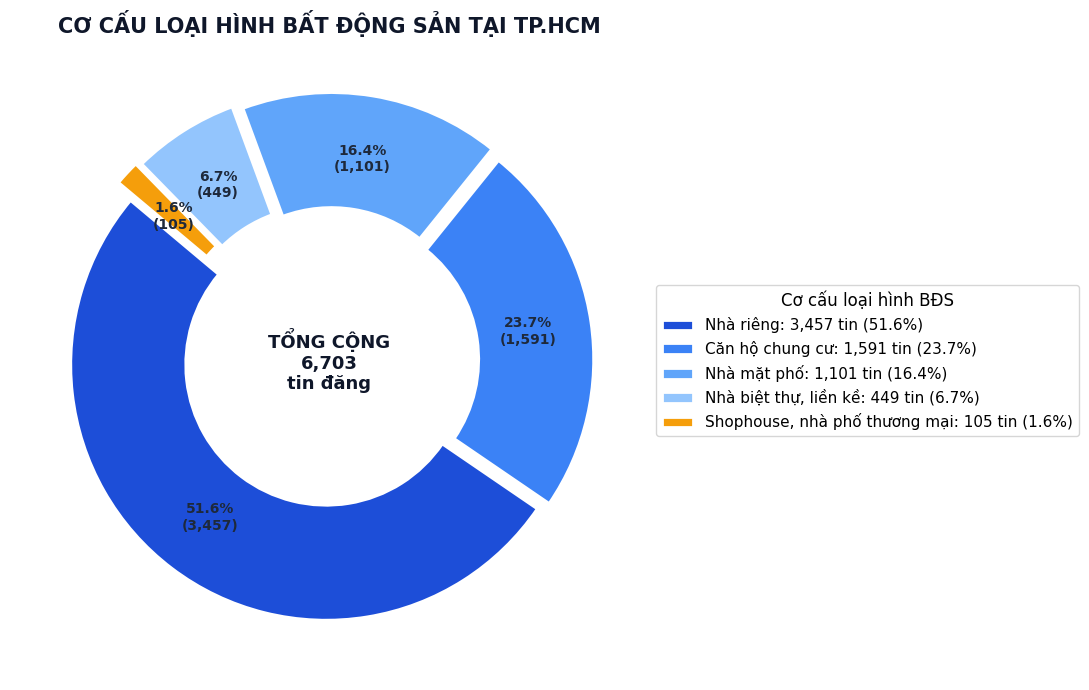

In [75]:
# Vẽ biểu đồ tròn (Donut Chart) với đầy đủ % và số lượng tin
fig, ax = plt.subplots(figsize=(10, 7))

labels = counts.index.tolist()
sizes = counts.values.tolist()
total = sum(sizes)
n_categories = len(labels)

# 1. Tự động sinh bảng màu hài hòa theo số lượng loại hình
base_palette = ['#1d4ed8', '#3b82f6', '#60a5fa', '#93c5fd', '#f59e0b', '#10b981', '#8b5cf6', '#ec4899']
colors = base_palette[:n_categories] if n_categories <= len(base_palette) else plt.cm.tab10(range(n_categories))

# 2. Tự động sinh độ giãn cách (explode) khớp với n_categories
explode = [0.02 + 0.015 * i for i in range(n_categories)]

def autopct_format(pct):
    val = int(round(pct * total / 100.0))
    return f"{pct:.1f}%\n({val:,})"

pie_result = ax.pie(
    sizes,
    labels=None,
    autopct=autopct_format,
    pctdistance=0.75,
    startangle=140,
    explode=explode,
    colors=colors,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)

wedges = pie_result[0]
autotexts = pie_result[2]

for autotext in autotexts:
    autotext.set_color('#1e293b')
    autotext.set_fontsize(10)
    autotext.set_weight('bold')

ax.text(0, 0, f"TỔNG CỘNG\n{total:,}\ntin đăng", ha='center', va='center', 
        fontsize=13, fontweight='bold', color='#0f172a')

# pcts tính từ counts để đảm bảo luôn khớp thứ tự
legend_labels = [f"{label}: {val:,} tin ({(val/total*100):.1f}%)" 
                 for label, val in zip(labels, sizes)]
ax.legend(
    wedges, 
    legend_labels,
    title="Cơ cấu loại hình BĐS",
    title_fontsize=12,
    fontsize=11,
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1),
    frameon=True
)

plt.title("CƠ CẤU LOẠI HÌNH BẤT ĐỘNG SẢN TẠI TP.HCM", fontsize=15, fontweight='bold', color='#0f172a')
plt.tight_layout()

img_pie = 'figures/property_type_chart.png' if os.path.exists('figures') else 'property_type_chart.png'
plt.savefig(img_pie, bbox_inches='tight')
plt.show()

## 2. Nhóm 1: Phân Tích Không Gian & Địa Lý (Spatial & Geographic Analysis)

### 2.1. Top 10 Phường / Xã (Đơn vị mới) dẫn đầu thị trường
Phân tích theo `district` (tên phường/xã mới) để nhận diện các điểm nóng giao dịch sau đợt sắp xếp địa giới hành chính.

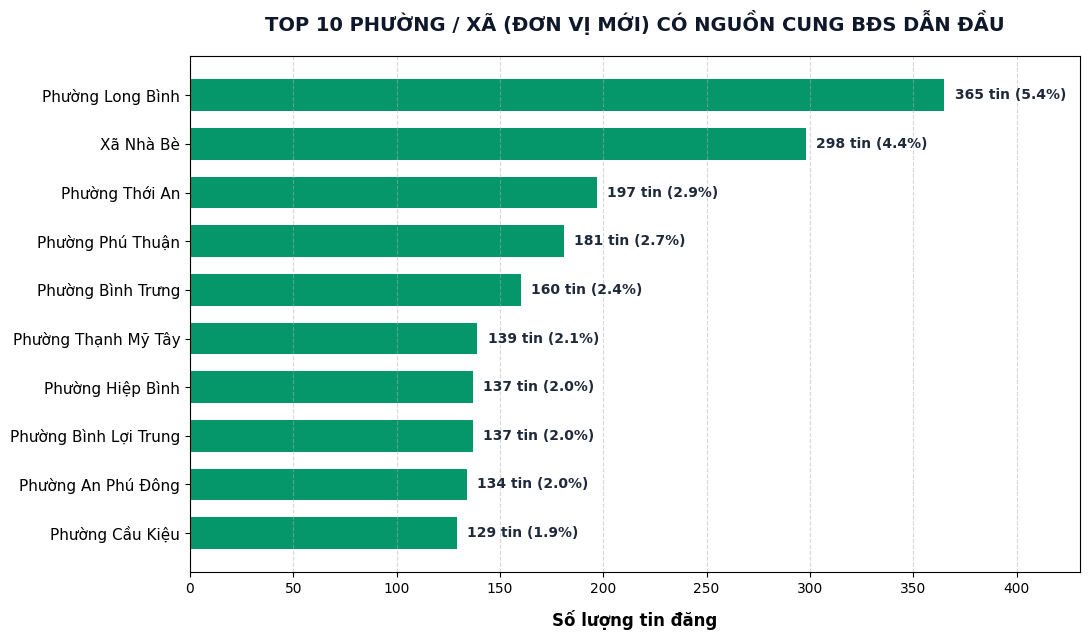

In [76]:
top_wards = df['district'].value_counts().head(10)
pct_wards = (top_wards / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(11, 6.5))
y_pos = np.arange(len(top_wards))
bars = ax.barh(y_pos, top_wards.values, color='#059669', edgecolor='none', height=0.65)
ax.invert_yaxis()
ax.set_yticks(y_pos)
ax.set_yticklabels(top_wards.index, fontsize=11, fontweight='500')
ax.set_xlabel('Số lượng tin đăng', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('TOP 10 PHƯỜNG / XÃ (ĐƠN VỊ MỚI) CÓ NGUỒN CUNG BĐS DẪN ĐẦU', fontsize=14, fontweight='bold', pad=18, color='#0f172a')

for bar, val, pct in zip(bars, top_wards.values, pct_wards):
    ax.text(val + 5, bar.get_y() + bar.get_height()/2, f"{val:,} tin ({pct:.1f}%)", 
            va='center', ha='left', fontsize=10, fontweight='bold', color='#1e293b')

ax.set_xlim(0, max(top_wards.values) * 1.18)
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()

img_ward = 'figures/group1_top_wards.png' if os.path.exists('figures') else 'group1_top_wards.png'
plt.savefig(img_ward, bbox_inches='tight')
plt.show()

---
## 3. Nhóm 2: Phân Tích Đơn Giá & Diện Tích (Price & Area Analysis)

### 3.1. Phân bố Đơn giá (Triệu VNĐ/m²) theo Loại hình BĐS
Tính toán đặc trưng đơn giá $\text{price\_per\_m2} = \frac{\text{price\_range} \times 1000}{\text{area}}$ và trực quan hóa phân bố bằng biểu đồ hộp (Boxplot) để so sánh trung vị và độ phân tán giá giữa các loại hình.

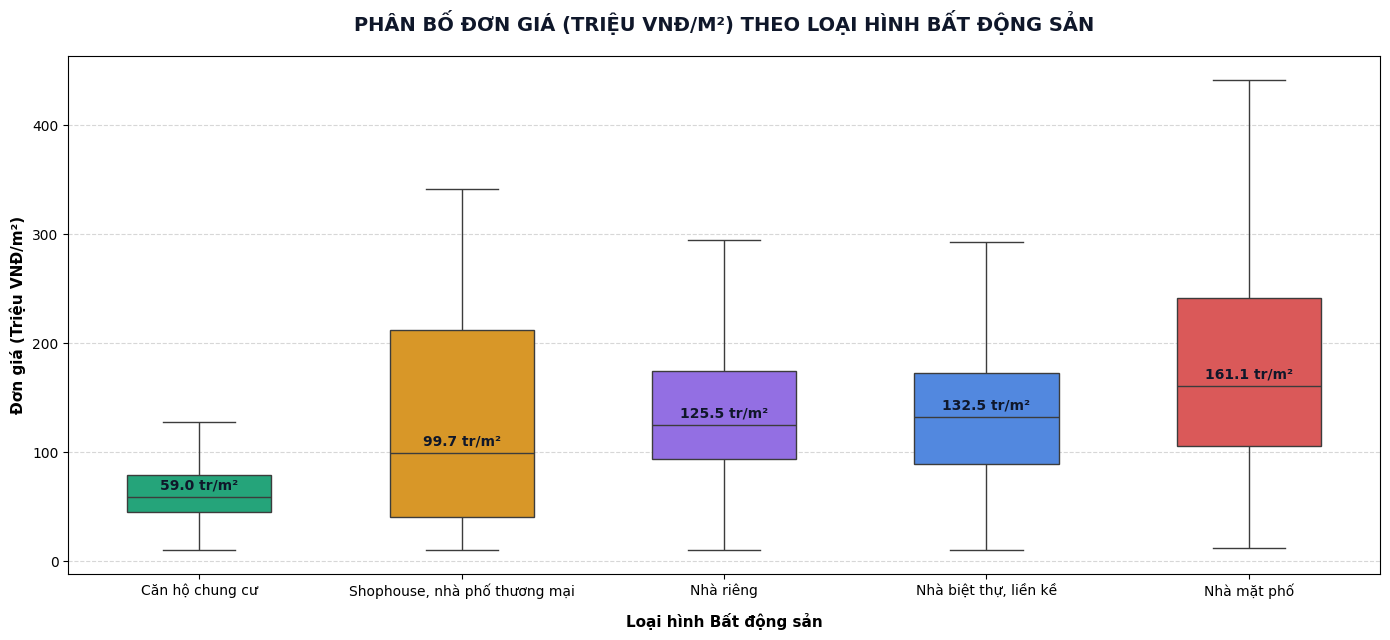

In [77]:
# Tính đơn giá triệu/m2
valid_df = df[df['price_range'].notna() & df['area'].notna() & (df['area'] > 0)].copy()
valid_df['price_per_m2'] = (valid_df['price_range'] * 1000) / valid_df['area']

# Lọc bớt nhiễu ngoại lai để quan sát rõ hộp phân bố (10 - 500 triệu/m2)
clean_df = valid_df[(valid_df['price_per_m2'] >= 10) & (valid_df['price_per_m2'] <= 500)].copy()
order = clean_df.groupby('property_type')['price_per_m2'].median().sort_values().index

fig, ax = plt.subplots(figsize=(14, 6.5))
palette = ['#3b82f6', '#10b981', '#f59e0b', '#8b5cf6', '#ef4444']
sns.boxplot(
    data=clean_df,
    x='property_type',
    y='price_per_m2',
    order=order,
    hue='property_type',
    palette=palette,
    showfliers=False,
    width=0.55,
    legend=False,
    ax=ax
)

# Chú thích giá trị trung vị (Median) trên từng cột hộp
medians = clean_df.groupby('property_type')['price_per_m2'].median()[order]
for idx, (p_type, med) in enumerate(medians.items()):
    ax.text(idx, med + 4, f"{med:.1f} tr/m²", ha='center', va='bottom', fontsize=10, fontweight='bold', color='#0f172a')

ax.set_title('PHÂN BỐ ĐƠN GIÁ (TRIỆU VNĐ/M²) THEO LOẠI HÌNH BẤT ĐỘNG SẢN', fontsize=14, fontweight='bold', pad=18, color='#0f172a')
ax.set_xlabel('Loại hình Bất động sản', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('Đơn giá (Triệu VNĐ/m²)', fontsize=11, fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

img_box = 'figures/group2_boxplot_price_per_m2.png' if os.path.exists('figures') else 'group2_boxplot_price_per_m2.png'
plt.savefig(img_box, bbox_inches='tight')
plt.show()

In [78]:
clean_df['property_type'].unique()

array(['Nhà biệt thự, liền kề', 'Căn hộ chung cư',
       'Shophouse, nhà phố thương mại', 'Nhà riêng', 'Nhà mặt phố'],
      dtype=object)

### 3.2. Top 10 Phường / Xã (Đơn vị mới) có Đơn giá BĐS đắt đỏ nhất TP.HCM
Xếp hạng các phường/xã mới sau sáp nhập (có từ 20 tin đăng trở lên) theo đơn giá trung vị để nhận diện các địa bàn có giá trị đất cao nhất.

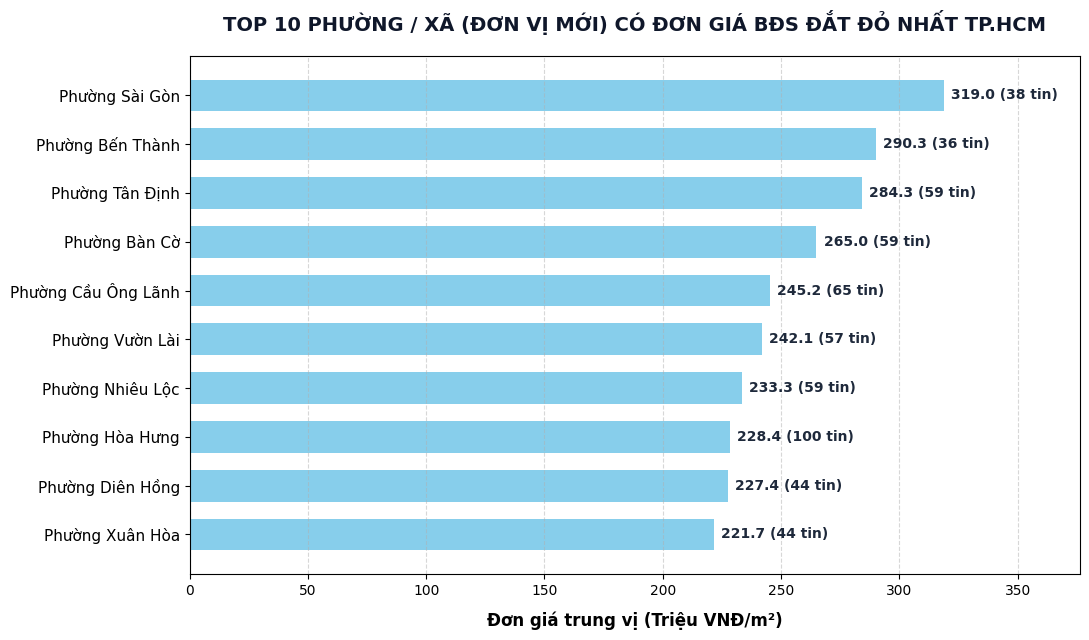

In [79]:
# Thống kê đơn giá trung vị theo phường/xã mới (cột district)
district_stats = clean_df.groupby('district')['price_per_m2'].agg(['count', 'median']).sort_values('median', ascending=False)
top_expensive = district_stats[district_stats['count'] >= 20].head(10)

fig, ax = plt.subplots(figsize=(11, 6.5))
y_pos = np.arange(len(top_expensive))

# Đổi sang màu xanh trời
bars = ax.barh(y_pos, top_expensive['median'].values, color='#87CEEB', edgecolor='none', height=0.65)

ax.invert_yaxis()
ax.set_yticks(y_pos)
ax.set_yticklabels(top_expensive.index, fontsize=11, fontweight='500')
ax.set_xlabel('Đơn giá trung vị (Triệu VNĐ/m²)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('TOP 10 PHƯỜNG / XÃ (ĐƠN VỊ MỚI) CÓ ĐƠN GIÁ BĐS ĐẮT ĐỎ NHẤT TP.HCM', fontsize=14, fontweight='bold', pad=18, color='#0f172a')

# Bỏ đơn vị tr/m² khỏi nhãn mỗi thanh
for bar, med, cnt in zip(bars, top_expensive['median'].values, top_expensive['count'].values):
    ax.text(med + 3, bar.get_y() + bar.get_height()/2, f"{med:.1f} ({cnt} tin)",
            va='center', ha='left', fontsize=10, fontweight='bold', color='#1e293b')

ax.set_xlim(0, max(top_expensive['median'].values) * 1.18)
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()

img_exp = 'figures/group2_top_expensive_districts.png' if os.path.exists('figures') else 'group2_top_expensive_districts.png'
plt.savefig(img_exp, bbox_inches='tight')
plt.show()

### 3.3. So sánh Cơ cấu Loại hình BĐS: Top 10 Nguồn cung vs. Top 10 Đắt đỏ (Địa chỉ mới)
Biểu đồ lưới 1 hàng 2 cột thể hiện tỷ lệ % các loại hình BĐS (Căn hộ chung cư, Nhà riêng, Nhà mặt phố, Biệt thự/liền kề, Shophouse):
* **Bên trái:** Top 10 Phường/Xã mới có **nguồn cung lớn nhất** (tập trung nhiều dự án chung cư và đại đô thị mới).
* **Bên phải:** Top 10 Phường/Xã mới **đắt đỏ nhất** theo đơn giá trung vị (áp đảo bởi nhà mặt phố và nhà riêng vùng lõi).

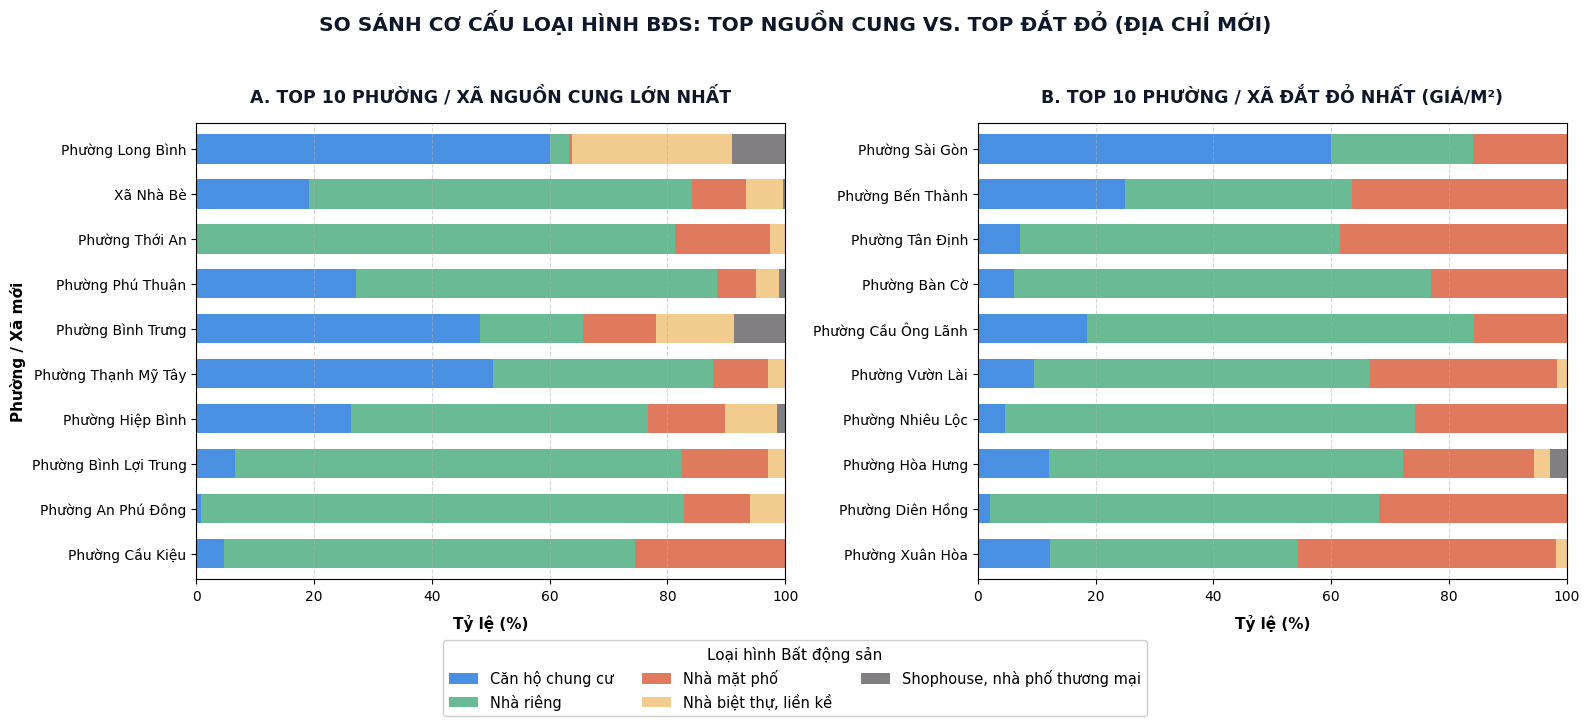

In [80]:
p_types = ['Căn hộ chung cư', 'Nhà riêng', 'Nhà mặt phố', 'Nhà biệt thự, liền kề', 'Shophouse, nhà phố thương mại']
# colors_ptype = ['#5b8def', '#52b788', '#e76f51', '#f4a261', '#9d8189']
colors_ptype = ['#4a90e2', '#68bb93', '#e07a5f', '#f2cc8f', '#817f82']

# 1. Top 10 phường/xã mới dẫn đầu Nguồn cung
top_supply = df['district'].value_counts().head(10).index
ct_supply = (pd.crosstab(df[df['district'].isin(top_supply)]['district'], df['property_type'], normalize='index') * 100).reindex(columns=p_types, fill_value=0).loc[top_supply]

# 2. Top 10 phường/xã mới Đắt đỏ nhất (có từ 20 tin trở lên)
stats_exp = clean_df.groupby('district')['price_per_m2'].agg(['count', 'median']).sort_values('median', ascending=False)
top_exp = stats_exp[stats_exp['count'] >= 20].head(10).index
ct_exp = (pd.crosstab(df[df['district'].isin(top_exp)]['district'], df['property_type'], normalize='index') * 100).reindex(columns=p_types, fill_value=0).loc[top_exp]

# 3. Vẽ biểu đồ lưới 1 hàng 2 cột
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Cột bên trái: Top 10 Nguồn cung
ct_supply.plot(kind='barh', stacked=True, color=colors_ptype, ax=ax1, width=0.65, legend=False)
ax1.invert_yaxis()
ax1.set_title('A. TOP 10 PHƯỜNG / XÃ NGUỒN CUNG LỚN NHẤT', fontsize=12.5, fontweight='bold', pad=15, color='#0f172a')
ax1.set_xlabel('Tỷ lệ (%)', fontsize=11, fontweight='bold', labelpad=8)
ax1.set_ylabel('Phường / Xã mới', fontsize=11, fontweight='bold')
ax1.set_xlim(0, 100)
ax1.grid(axis='x', linestyle='--', alpha=0.5)

# Cột bên phải: Top 10 Đắt đỏ
ct_exp.plot(kind='barh', stacked=True, color=colors_ptype, ax=ax2, width=0.65, legend=False)
ax2.invert_yaxis()
ax2.set_title('B. TOP 10 PHƯỜNG / XÃ ĐẮT ĐỎ NHẤT (GIÁ/M²)', fontsize=12.5, fontweight='bold', pad=15, color='#0f172a')
ax2.set_xlabel('Tỷ lệ (%)', fontsize=11, fontweight='bold', labelpad=8)
ax2.set_ylabel('')
ax2.set_xlim(0, 100)
ax2.grid(axis='x', linestyle='--', alpha=0.5)

# Legend chung ở dưới
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.04),
           title='Loại hình Bất động sản', title_fontsize=11, fontsize=10.5, frameon=True, framealpha=0.95)

plt.suptitle('SO SÁNH CƠ CẤU LOẠI HÌNH BĐS: TOP NGUỒN CUNG VS. TOP ĐẮT ĐỎ (ĐỊA CHỈ MỚI)', 
             fontsize=14.5, fontweight='bold', y=0.98, color='#0f172a')
plt.tight_layout(rect=[0, 0.07, 1, 0.95])

img_ptype = 'figures/group2_property_type_comparison.png' if os.path.exists('figures') else 'group2_property_type_comparison.png'
plt.savefig(img_ptype, bbox_inches='tight')
plt.show()

---
## 4. Nhóm 3: Phân Tích Xu Hướng & Nhịp Độ Thời Gian (Temporal & Trend Analysis)

### 4.1. Xu hướng Số lượng Tin đăng theo Thời gian
Chuyển đổi `posted_date` sang kiểu dữ liệu datetime để theo dõi biến động nguồn cung tin đăng hàng ngày từ tháng 08/2026 đến tháng 10/2026.

In [87]:
# import matplotlib.dates as mdates
# # Chuyển đổi định dạng ngày đăng tin
# df['posted_dt'] = pd.to_datetime(df['posted_date'], format='%d/%m/%Y')
# daily_counts = df.groupby(df['posted_dt'].dt.date).size()
# daily_df = pd.DataFrame({'date': pd.to_datetime(daily_counts.index), 'count': daily_counts.values})

# fig, ax = plt.subplots(figsize=(10, 6))
# ax.plot(daily_df['date'], daily_df['count'], color='#2563eb', linewidth=2.5, marker='o', markersize=4, label='Số tin đăng hàng ngày')
# ax.fill_between(daily_df['date'], daily_df['count'], color='#3b82f6', alpha=0.18)

# ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
# ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
# plt.xticks(rotation=0, fontsize=10)

# ax.set_title('XU HƯỚNG SỐ LƯỢNG TIN ĐĂNG BẤT ĐỘNG SẢN THEO THỜI GIAN', fontsize=14, fontweight='bold', pad=18, color='#0f172a')
# ax.set_xlabel('Thời gian đăng tin (Ngày/Tháng trong năm 2026)', fontsize=11, fontweight='bold', labelpad=10)
# ax.set_ylabel('Số lượng tin đăng', fontsize=11, fontweight='bold')
# ax.grid(True, linestyle='--', alpha=0.5)

# # Gắn nhãn đỉnh cao điểm
# peak_row = daily_df.loc[daily_df['count'].idxmax()]
# ax.annotate(f"Đỉnh cao nhất: {peak_row['count']} tin\n({peak_row['date'].strftime('%d/%m/%Y')})",
#             xy=(peak_row['date'], peak_row['count']),
#             xytext=(peak_row['date'] - pd.Timedelta(days=8), peak_row['count'] + 25),
#             arrowprops=dict(facecolor='#dc2626', shrink=0.08, width=1.5, headwidth=6),
#             fontsize=10, fontweight='bold', color='#dc2626')

# ax.set_ylim(0, max(daily_df['count']) * 1.18)
# plt.tight_layout()

# img_ts = 'figures/group3_timeseries_daily_listings.png' if os.path.exists('figures') else 'group3_timeseries_daily_listings.png'
# plt.savefig(img_ts, bbox_inches='tight')
# plt.show()

### 4.2. Nhịp độ Đăng tin theo Ngày trong tuần (Day of Week Distribution)
Phân tích hành vi đăng tải của môi giới và chủ nhà để xác định ngày nào trong tuần có lượng tương tác và cập nhật thông tin sôi động nhất.

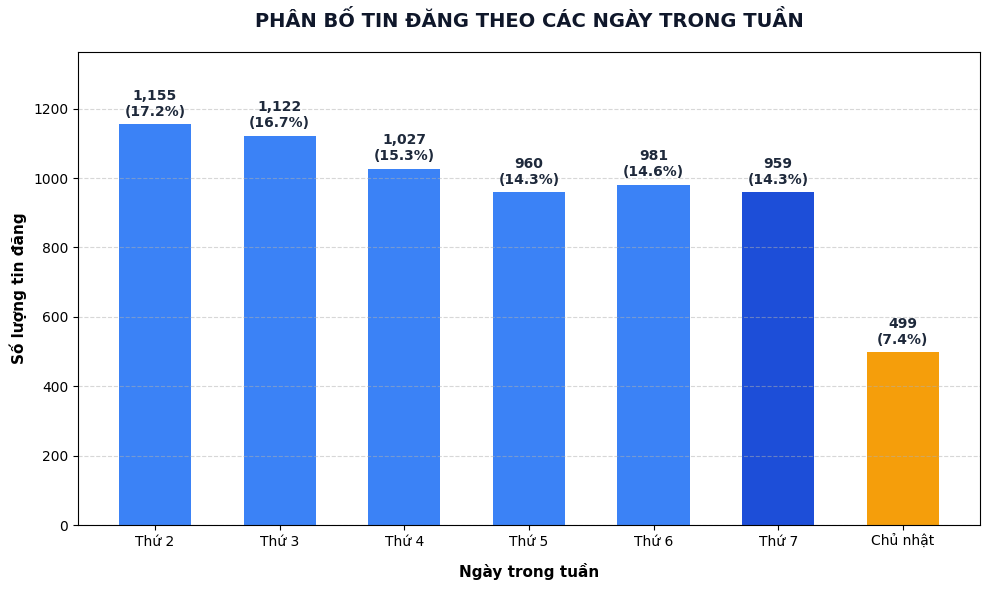

In [82]:
# Trích xuất thứ trong tuần
df['day_name'] = df['posted_dt'].dt.day_name()
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
vn_days = ['Thứ 2', 'Thứ 3', 'Thứ 4', 'Thứ 5', 'Thứ 6', 'Thứ 7', 'Chủ nhật']
day_counts = df['day_name'].value_counts().reindex(days_order)
day_pcts = (day_counts / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#3b82f6', '#3b82f6', '#3b82f6', '#3b82f6', '#3b82f6', '#1d4ed8', '#f59e0b']
bars = ax.bar(vn_days, day_counts.values, color=colors, width=0.58)

for bar, val, pct in zip(bars, day_counts.values, day_pcts.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 15, f"{val:,}\n({pct:.1f}%)",
            ha='center', va='bottom', fontsize=10, fontweight='bold', color='#1e293b')

ax.set_title('PHÂN BỐ TIN ĐĂNG THEO CÁC NGÀY TRONG TUẦN', fontsize=14, fontweight='bold', pad=18, color='#0f172a')
ax.set_xlabel('Ngày trong tuần', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('Số lượng tin đăng', fontsize=11, fontweight='bold')
ax.set_ylim(0, max(day_counts.values) * 1.18)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

img_dow = 'figures/group3_day_of_week_distribution.png' if os.path.exists('figures') else 'group3_day_of_week_distribution.png'
plt.savefig(img_dow, bbox_inches='tight')
plt.show()

### 4.3. Cơ cấu Thời hạn Niêm yết Tin đăng (Listing Duration)
Khoảng thời gian hiệu lực giữa ngày đăng (`posted_date`) và ngày hết hạn (`expiry_date`) thể hiện cấu trúc các gói dịch vụ niêm yết được sử dụng phổ biến nhất.

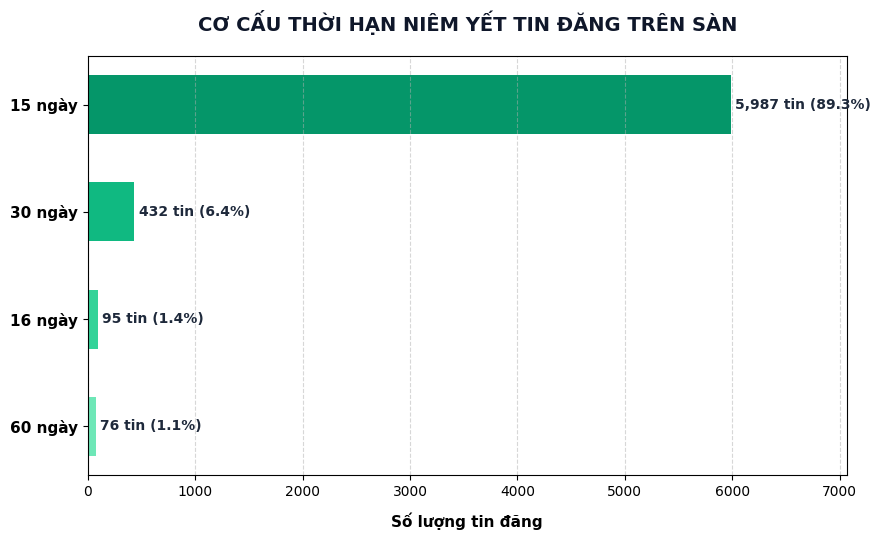

In [83]:
# Tính số ngày hiệu lực của tin đăng
df['expiry_dt'] = pd.to_datetime(df['expiry_date'], format='%d/%m/%Y')
df['duration_days'] = (df['expiry_dt'] - df['posted_dt']).dt.days
dur_counts = df['duration_days'].value_counts().head(4)
dur_labels = [f"{int(d)} ngày" for d in dur_counts.index]
dur_pcts = (dur_counts / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 5.5))
colors_dur = ['#059669', '#10b981', '#34d399', '#6ee7b7']
y_pos = np.arange(len(dur_counts))
bars = ax.barh(y_pos, dur_counts.values, color=colors_dur, edgecolor='none', height=0.55)
ax.invert_yaxis()
ax.set_yticks(y_pos)
ax.set_yticklabels(dur_labels, fontsize=11, fontweight='bold')
ax.set_xlabel('Số lượng tin đăng', fontsize=11, fontweight='bold', labelpad=10)
ax.set_title('CƠ CẤU THỜI HẠN NIÊM YẾT TIN ĐĂNG TRÊN SÀN', fontsize=14, fontweight='bold', pad=18, color='#0f172a')

for bar, val, pct in zip(bars, dur_counts.values, dur_pcts.values):
    ax.text(val + 40, bar.get_y() + bar.get_height()/2, f"{val:,} tin ({pct:.1f}%)",
            va='center', ha='left', fontsize=10, fontweight='bold', color='#1e293b')

ax.set_xlim(0, max(dur_counts.values) * 1.18)
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()

img_dur = 'figures/group3_listing_duration.png' if os.path.exists('figures') else 'group3_listing_duration.png'
plt.savefig(img_dur, bbox_inches='tight')
plt.show()

---
## 5. Nhóm 4: Thuộc Tính Bất Động Sản, Pháp Lý & Thị Hiếu (Property Specs & Feng Shui)

### 5.1. Phân bố Hướng nhà & Hướng ban công (Radar Chart Phong Thủy)
Khảo sát phân bố 8 hướng của ngôi nhà và ban công bằng biểu đồ mạng nhện (Radar Chart) để đánh giá thị hiếu lựa chọn hướng vi khí hậu (đón gió Nam/Đông Nam, tránh nắng Tây).

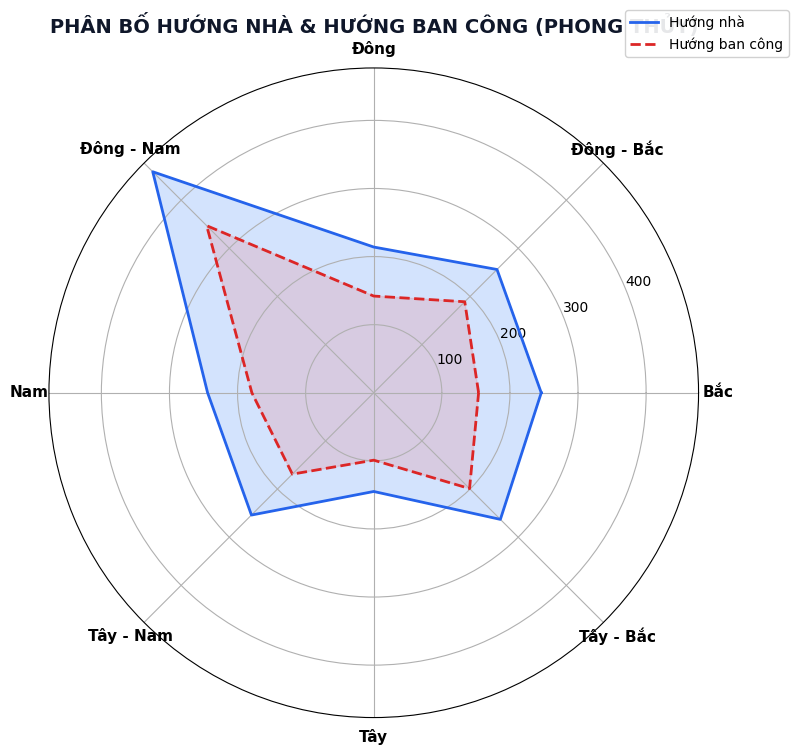

In [84]:
# 1. Vẽ biểu đồ mạng nhện 8 hướng
directions = ['Bắc', 'Đông - Bắc', 'Đông', 'Đông - Nam', 'Nam', 'Tây - Nam', 'Tây', 'Tây - Bắc']
house_counts = df['house_direction'].value_counts().reindex(directions).fillna(0)
balcony_counts = df['balcony_direction'].value_counts().reindex(directions).fillna(0)

angles = np.linspace(0, 2 * np.pi, len(directions), endpoint=False).tolist()
# Khép kín vòng tròn đa giác
angles += angles[:1]
house_vals = house_counts.tolist() + house_counts.tolist()[:1]
balcony_vals = balcony_counts.tolist() + balcony_counts.tolist()[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
ax.plot(angles, house_vals, color='#2563eb', linewidth=2, label='Hướng nhà')
ax.fill(angles, house_vals, color='#3b82f6', alpha=0.22)

ax.plot(angles, balcony_vals, color='#dc2626', linewidth=2, linestyle='--', label='Hướng ban công')
ax.fill(angles, balcony_vals, color='#ef4444', alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(directions, fontsize=11, fontweight='bold')
ax.set_title('PHÂN BỐ HƯỚNG NHÀ & HƯỚNG BAN CÔNG (PHONG THỦY)', fontsize=14, fontweight='bold', pad=25, color='#0f172a')
ax.legend(loc='upper right', bbox_to_anchor=(1.15, 1.1), fontsize=10, framealpha=0.9)
plt.tight_layout()

img_radar = 'figures/group4_radar_directions.png' if os.path.exists('figures') else 'group4_radar_directions.png'
plt.savefig(img_radar, bbox_inches='tight')
plt.show()

### 5.2. Cơ cấu Số phòng ngủ theo Loại hình Bất động sản
So sánh quy mô số phòng ngủ (1PN, 2PN, 3PN, 4PN, 5PN+) giữa Căn hộ chung cư, Nhà riêng và Nhà mặt phố.

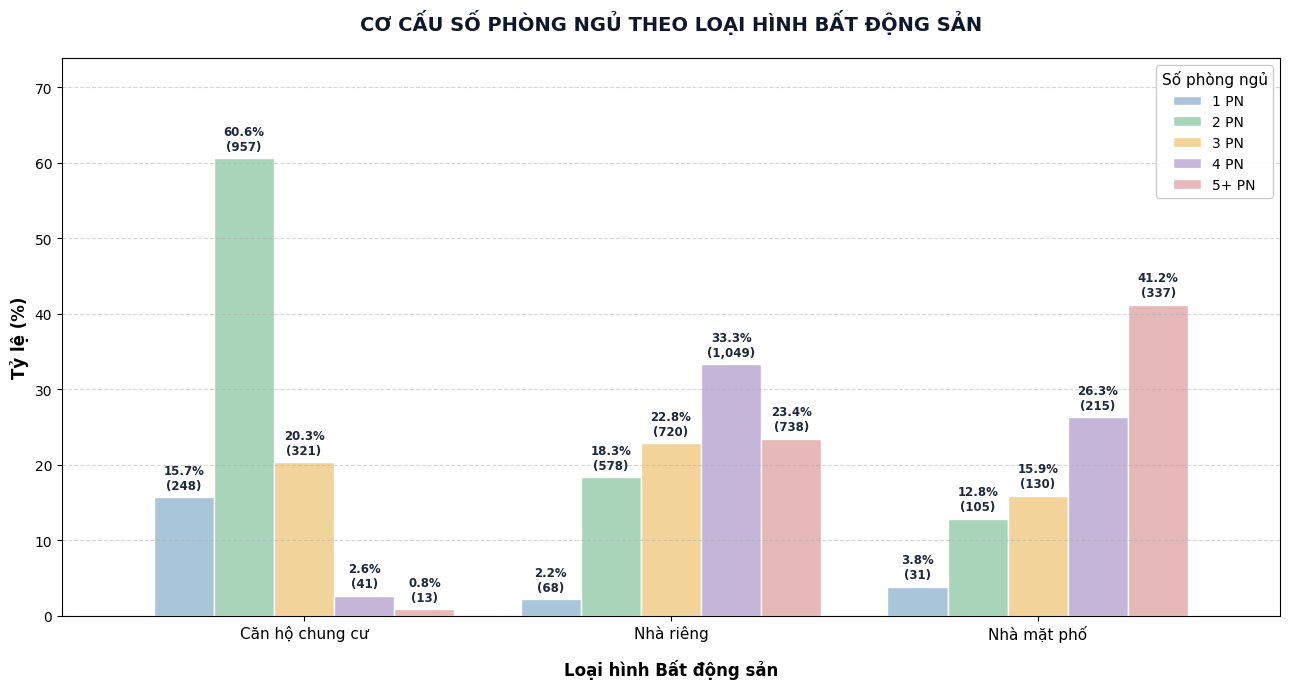

In [85]:
# Gom nhóm số phòng ngủ
def group_bedrooms(val):
    if pd.isna(val): return np.nan
    val = int(val)
    if val <= 1: return '1 PN'
    elif val == 2: return '2 PN'
    elif val == 3: return '3 PN'
    elif val == 4: return '4 PN'
    else: return '5+ PN'

df['bed_group'] = df['bedrooms'].apply(group_bedrooms)
bed_order = ['1 PN', '2 PN', '3 PN', '4 PN', '5+ PN']
p_types = ['Căn hộ chung cư', 'Nhà riêng', 'Nhà mặt phố']

bed_df = df[df['property_type'].isin(p_types) & df['bed_group'].notna()]
ct_pct = pd.crosstab(bed_df['property_type'], bed_df['bed_group'], normalize='index')[bed_order].loc[p_types] * 100
ct_cnt = pd.crosstab(bed_df['property_type'], bed_df['bed_group'])[bed_order].loc[p_types]

fig, ax = plt.subplots(figsize=(13, 7))
# Bộ màu tương phản rõ nét cho 5 nhóm phòng ngủ (tránh bị trùng màu trắng nền)
colors = ['#A8C5DA', '#A8D5BA', '#F2D49B', '#C5B5D9', '#E6B8B7']

ct_pct.plot(kind='bar', ax=ax, width=0.82, color=colors, edgecolor='white', linewidth=1)

# Ghi tỷ lệ % (1 chữ số thập phân) và số lượng tin (trong ngoặc) trên đầu mỗi cột
for c_idx, container in enumerate(ax.containers):
    bed_name = bed_order[c_idx]
    for p_idx, bar in enumerate(container):
        p_type = p_types[p_idx]
        pct = ct_pct.loc[p_type, bed_name]
        cnt = ct_cnt.loc[p_type, bed_name]
        height = bar.get_height()
        if height > 0:
            ax.annotate(f"{pct:.1f}%\n({cnt:,})",
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 4),
                        textcoords='offset points',
                        ha='center', va='bottom',
                        fontsize=8.5, fontweight='bold', color='#1e293b')

ax.set_title('CƠ CẤU SỐ PHÒNG NGỦ THEO LOẠI HÌNH BẤT ĐỘNG SẢN', fontsize=14, fontweight='bold', pad=20, color='#0f172a')
ax.set_xlabel('Loại hình Bất động sản', fontsize=12, fontweight='bold', labelpad=12)
ax.set_ylabel('Tỷ lệ (%)', fontsize=12, fontweight='bold')
plt.xticks(rotation=0, fontsize=11, fontweight='500')
ax.set_ylim(0, max(ct_pct.values.flatten()) * 1.22)
ax.legend(title='Số phòng ngủ', title_fontsize=11, fontsize=10, loc='upper right', framealpha=0.95)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

img_bed = 'figures/group4_bedrooms_distribution.png' if os.path.exists('figures') else 'group4_bedrooms_distribution.png'
plt.savefig(img_bed, bbox_inches='tight')
plt.show()

### 5.3. So sánh Cơ cấu Pháp lý: Top 10 Nguồn cung vs. Top 10 Đắt đỏ (Địa chỉ mới)
Biểu đồ lưới 1 hàng 2 cột thể hiện tỷ lệ % các loại hình pháp lý (Sổ đỏ/hồng riêng, HĐMB, Sổ chung, Khác):
* **Bên trái:** Top 10 Phường/Xã mới có **nguồn cung lớn nhất** (thể hiện bức tranh toàn cảnh các dự án mới & thổ cư ven).
* **Bên phải:** Top 10 Phường/Xã mới **đắt đỏ nhất** theo đơn giá trung vị (khẳng định chuẩn mực pháp lý tại vùng lõi giá trị cao).

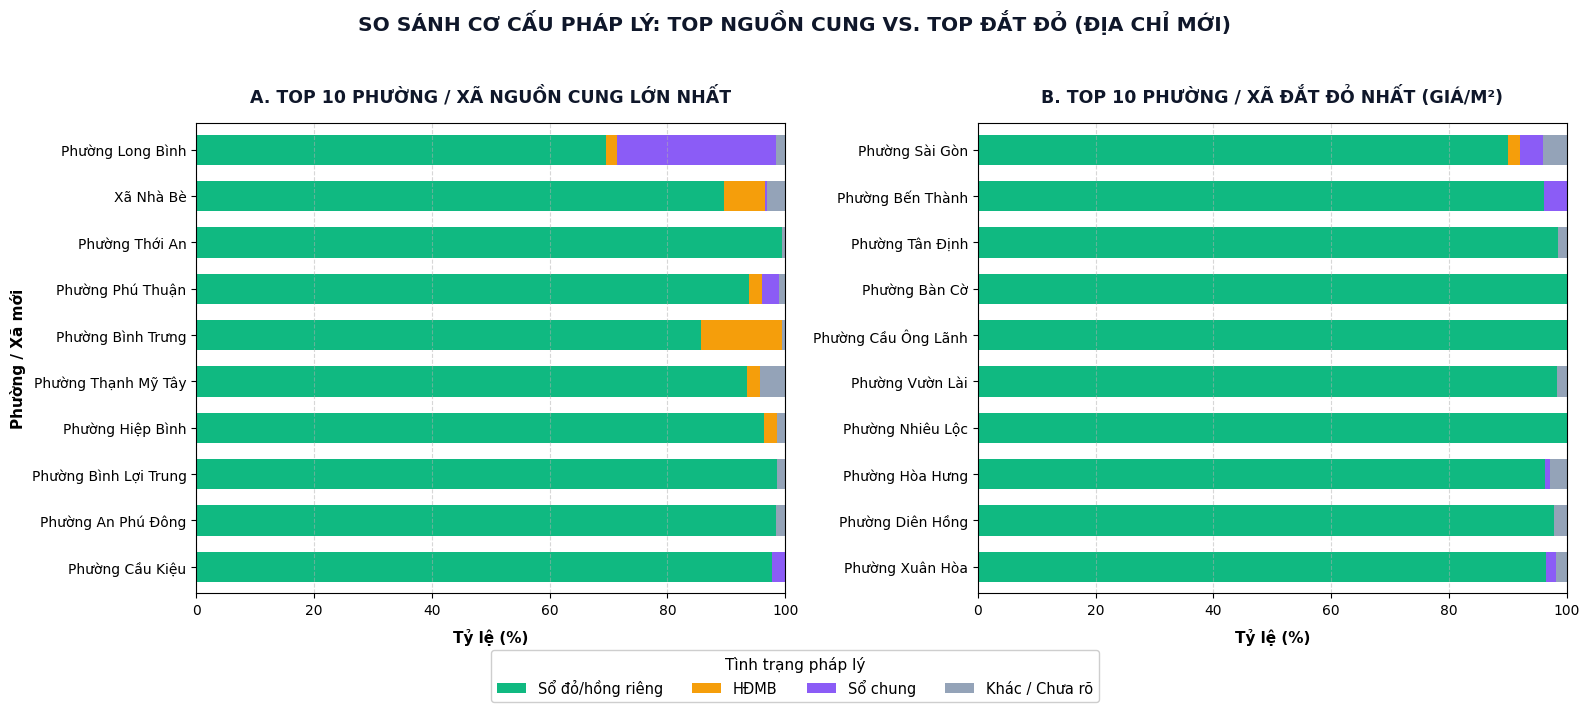

In [86]:
# Chuẩn hóa tình trạng pháp lý
def clean_legal(val):
    if pd.isna(val): return 'Khác / Chưa rõ'
    v = str(val).lower()
    if 'hợp đồng mua bán' in v or 'hdmb' in v: return 'HĐMB'
    if 'chung' in v: return 'Sổ chung'
    if 'sổ' in v or 'so' in v: return 'Sổ đỏ/hồng riêng'
    return 'Khác / Chưa rõ'

df['clean_legal'] = df['legal_status'].apply(clean_legal)
cols = ['Sổ đỏ/hồng riêng', 'HĐMB', 'Sổ chung', 'Khác / Chưa rõ']
colors_legal = ['#10b981', '#f59e0b', '#8b5cf6', '#94a3b8']

# 1. Top 10 phường/xã mới dẫn đầu Nguồn cung
top_supply = df['district'].value_counts().head(10).index
ct_supply = (pd.crosstab(df[df['district'].isin(top_supply)]['district'], df['clean_legal'], normalize='index') * 100).reindex(columns=cols, fill_value=0).loc[top_supply]

# 2. Top 10 phường/xã mới Đắt đỏ nhất (có từ 20 tin trở lên)
stats_exp = clean_df.groupby('district')['price_per_m2'].agg(['count', 'median']).sort_values('median', ascending=False)
top_exp = stats_exp[stats_exp['count'] >= 20].head(10).index
ct_exp = (pd.crosstab(df[df['district'].isin(top_exp)]['district'], df['clean_legal'], normalize='index') * 100).reindex(columns=cols, fill_value=0).loc[top_exp]

# 3. Vẽ biểu đồ lưới 1 hàng 2 cột
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Cột bên trái: Top 10 Nguồn cung
ct_supply.plot(kind='barh', stacked=True, color=colors_legal, ax=ax1, width=0.65, legend=False)
ax1.invert_yaxis()
ax1.set_title('A. TOP 10 PHƯỜNG / XÃ NGUỒN CUNG LỚN NHẤT', fontsize=12.5, fontweight='bold', pad=15, color='#0f172a')
ax1.set_xlabel('Tỷ lệ (%)', fontsize=11, fontweight='bold', labelpad=8)
ax1.set_ylabel('Phường / Xã mới', fontsize=11, fontweight='bold')
ax1.set_xlim(0, 100)
ax1.grid(axis='x', linestyle='--', alpha=0.5)

# Cột bên phải: Top 10 Đắt đỏ
ct_exp.plot(kind='barh', stacked=True, color=colors_legal, ax=ax2, width=0.65, legend=False)
ax2.invert_yaxis()
ax2.set_title('B. TOP 10 PHƯỜNG / XÃ ĐẮT ĐỎ NHẤT (GIÁ/M²)', fontsize=12.5, fontweight='bold', pad=15, color='#0f172a')
ax2.set_xlabel('Tỷ lệ (%)', fontsize=11, fontweight='bold', labelpad=8)
ax2.set_ylabel('')
ax2.set_xlim(0, 100)
ax2.grid(axis='x', linestyle='--', alpha=0.5)

# Legend chung ở dưới
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.02),
           title='Tình trạng pháp lý', title_fontsize=11, fontsize=10.5, frameon=True, framealpha=0.95)

plt.suptitle('SO SÁNH CƠ CẤU PHÁP LÝ: TOP NGUỒN CUNG VS. TOP ĐẮT ĐỎ (ĐỊA CHỈ MỚI)', 
             fontsize=14.5, fontweight='bold', y=0.98, color='#0f172a')
plt.tight_layout(rect=[0, 0.05, 1, 0.95])

img_leg = 'figures/group4_legal_status_by_district.png' if os.path.exists('figures') else 'group4_legal_status_by_district.png'
plt.savefig(img_leg, bbox_inches='tight')
plt.show()